# 02. prior의 흐름 — v1에서 3.5까지 한 표로

PFN은 prior에서 뽑은 합성 데이터셋으로만 학습하므로, 모델이 무엇을 할 줄 아는지는 prior가 정합니다. 이 노트북은 [01 모델 구조의 흐름](01_architecture_evolution.ipynb)처럼 축 하나만 따라갑니다. 버전마다 이 저장소가 실제로 쓰는 prior에서 데이터셋을 뽑아, 데이터셋이 어떻게 생겼는지, 표 크기가 어떻게 정해지는지, 만드는 데 얼마나 걸리는지를 나란히 봅니다.

흐름은 이렇습니다. v1은 MLP로 만든 SCM·BNN과 GP를 섞은 prior bag으로 분류 데이터셋만 만들었습니다. v2 논문은 무작위 그래프 위의 SCM에 범주형 feature, 결측값, 계단 모양 관계를 넣고 회귀까지 만들었지만 코드를 공개하지 않았습니다. 그래서 이 저장소는 v2부터 3.5까지 같은 계열의 공개 prior인 TabICL graph SCM을 씁니다. 2.5는 생성기는 그대로 두고 표 크기를 키웠고, 3·3.5도 생성기와 표 크기가 v2와 같습니다. 3.5는 분류와 회귀 prior를 둘 다 써서 한 모델을 학습합니다.

각 칸의 자세한 설명은 [노트북 로드맵의 축별로 보기 표](../README.md#축별로-보기)의 prior 줄에서 이어지는 노트북에 있습니다.

다루는 흐름:

1. 버전마다 무엇을 쓰나 — 생성기와 표 크기 설정
2. 데이터셋 하나씩 보기
3. 표 크기는 어떻게 정해지나
4. 데이터셋 200개의 통계
5. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/axes/` 아래에 있으므로 저장소 루트는 두 단계 위입니다. graph SCM prior는 `tabicl` 패키지가 필요합니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from minipfn import set_seed
from minipfn.priors.graph_scm import GraphSCMPrior
from minipfn.priors.table_size import sample_table_size
from minipfn.recipes import tabpfn_v1, tabpfn_v2, tabpfn_v3

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.

## 1. 버전마다 무엇을 쓰나 — 생성기와 표 크기 설정

학습 설정에서 prior에 관한 값만 꺼내 한 표로 놓습니다. v1은 `recipes/tabpfn_v1.py`의 상수, v2·3·3.5는 각 recipe의 `paper`, 2.5는 `paper`로 학습한 뒤 긴 표로 이어 학습하는 `long_tables`입니다. 3.5 multitask 설정은 `task_configs()`로 분류용과 회귀용 두 설정으로 나뉩니다.

In [3]:
v2_paper = tabpfn_v2.paper("classification")
v25_long = tabpfn_v2.long_tables("classification", "v2.5")
v35 = tabpfn_v3.paper("multitask", "v3.5")
print("3.5 multitask가 나누는 task:", list(v35.task_configs()))


def graph_row(config, note):
    rows = "log 균등" if config.log_uniform_rows else "균등"
    return {
        "생성기": "TabICL graph SCM (`graph_scm`)",
        "task": note,
        "학습 행 수": f"{config.min_train_rows}~{config.max_train_rows:,} {rows}",
        "검증 행 수": f"{config.n_eval_rows}",
        "feature 수": f"Beta(0.95, 8) × {config.feature_scale}, 상한 {config.max_features}",
        "셀 수 상한": f"{config.max_cells:,}",
        "결측값": f"데이터셋 {config.missing_dataset_prob:.0%}에 MCAR",
    }


v1_max_train = tabpfn_v1.MAX_EVAL_POS - 1
prior_table = {
    "v1": {
        "생성기": "prior bag: MLP(SCM 또는 BNN) + GP",
        "task": "분류",
        "학습 행 수": f"1~{v1_max_train} 균등",
        "검증 행 수": f"{tabpfn_v1.SEQ_LEN} − 학습 행",
        "feature 수": f"균등 1~{tabpfn_v1.MAX_FEATURES} (100칸으로 0 채움)",
        "셀 수 상한": "—",
        "결측값": "없음 (공개 체크포인트 설정)",
    },
    "v2": graph_row(v2_paper, "분류, 회귀 (모델 따로)"),
    "v2.5": graph_row(v25_long, "분류, 회귀 (모델 따로)"),
    "v3": graph_row(tabpfn_v3.paper("classification", "v3"), "분류, 회귀 (모델 따로)"),
    "v3.5": graph_row(v35, "분류 + 회귀 (step마다 번갈아)"),
}
display(pd.DataFrame(prior_table).T)

3.5 multitask가 나누는 task: ['classification', 'regression']


,생성기,task,학습 행 수,검증 행 수,feature 수,셀 수 상한,결측값
v1,prior bag: MLP(SCM 또는 BNN) + GP,분류,1~999 균등,1152 − 학습 행,균등 1~100 (100칸으로 0 채움),—,없음 (공개 체크포인트 설정)
v2,TabICL graph SCM (`graph_scm`),"분류, 회귀 (모델 따로)","1~2,048 균등",128,"Beta(0.95, 8) × 160, 상한 160","75,000",데이터셋 30%에 MCAR
v2.5,TabICL graph SCM (`graph_scm`),"분류, 회귀 (모델 따로)","512~8,192 log 균등",128,"Beta(0.95, 8) × 500, 상한 500","400,000",데이터셋 30%에 MCAR
v3,TabICL graph SCM (`graph_scm`),"분류, 회귀 (모델 따로)","1~2,048 균등",128,"Beta(0.95, 8) × 160, 상한 160","75,000",데이터셋 30%에 MCAR
v3.5,TabICL graph SCM (`graph_scm`),분류 + 회귀 (step마다 번갈아),"1~2,048 균등",128,"Beta(0.95, 8) × 160, 상한 160","75,000",데이터셋 30%에 MCAR


생성기는 v1의 prior bag에서 v2의 graph SCM으로 한 번 바뀌고, 그 뒤로는 그대로입니다. 버전 사이에 바뀌는 것은 표 크기 규칙과 task입니다. 2.5만 학습 행을 512~8,192개, feature를 500개까지 늘린 긴 표로 이어 학습하고(학습 행은 log 균등), 3·3.5는 v2와 같은 크기로 학습합니다. 표의 v2 줄은 이 저장소가 쓰는 prior입니다. v2 논문의 prior는 [03_tabpfn_v2/03](../03_tabpfn_v2/03_prior_graph_and_edges.ipynb)·[04](../03_tabpfn_v2/04_prior_from_graph_to_table.ipynb)에서 작게 다시 만들어 봤고, TabICL prior와 무엇이 같고 다른지는 [03_tabpfn_v2/07](../03_tabpfn_v2/07_tabicl_prior.ipynb)에 있습니다.

## 2. 데이터셋 하나씩 보기

v1 prior bag, graph SCM 분류, graph SCM 회귀에서 학습 행 256개, 검증 행 128개짜리 데이터셋을 하나씩 뽑습니다. v1은 하이퍼파라미터를 공유하는 데이터셋 8개를 한 묶음(group)으로 만들고, graph SCM은 같은 크기의 데이터셋 8개를 한 batch로 만듭니다. 각 묶음의 첫 데이터셋에서 앞 두 feature를 그립니다.

v1 묶음: (8, 384, 100), 생성기 BNN, 쓰는 feature 79개


graph SCM 분류 batch: (8, 384, 5), 회귀 batch: (8, 384, 5)


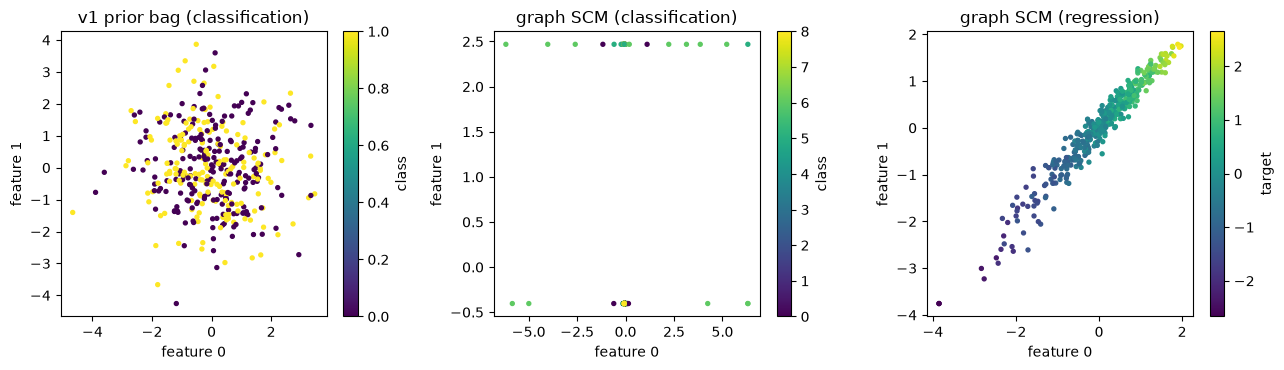

In [4]:
N_TRAIN, N_EVAL = 256, 128

v1_prior = tabpfn_v1.TabPFNPrior(seq_len=N_TRAIN + N_EVAL, seed=0)
x1, y1, hp1 = v1_prior.sample_group(N_TRAIN)  # x (8, 행, 100), y (8, 행), 공유 하이퍼파라미터
kind = "GP" if not hp1["use_mlp"] else ("SCM" if hp1["is_causal"] else "BNN")
print(f"v1 묶음: {tuple(x1.shape)}, 생성기 {kind}, 쓰는 feature {hp1['num_features_used']}개")

graph_cls = GraphSCMPrior("classification", seed=0)
graph_reg = GraphSCMPrior("regression", seed=0)
batch_cls = graph_cls.sample_batch(8, size=(N_TRAIN, 5))
batch_reg = graph_reg.sample_batch(8, size=(N_TRAIN, 5))
print(f"graph SCM 분류 batch: {tuple(batch_cls.x.shape)}, 회귀 batch: {tuple(batch_reg.x.shape)}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
panels = [
    ("v1 prior bag (classification)", x1[0], y1[0], "class"),
    ("graph SCM (classification)", batch_cls.x[0], batch_cls.y[0], "class"),
    ("graph SCM (regression)", batch_reg.x[0], batch_reg.y[0], "target"),
]
for ax, (title, xs, ys, label) in zip(axes, panels, strict=True):
    keep = ys >= 0 if label == "class" else torch.ones_like(ys, dtype=torch.bool)
    points = ax.scatter(xs[keep, 0], xs[keep, 1], c=ys[keep], s=8, cmap="viridis")
    fig.colorbar(points, ax=ax, label=label)
    ax.set_title(title)
    ax.set_xlabel("feature 0")
    ax.set_ylabel("feature 1")
plt.tight_layout()
plt.show()

v1 데이터셋은 값이 연속적으로 퍼져 있고 결측값이 없습니다. feature는 100칸으로 0을 채워 들어가므로, 실제로 쓰는 열 수는 하이퍼파라미터 `num_features_used`로 따로 정해집니다. graph SCM 데이터셋은 값이 몇 개로 뭉친 열(범주형이나 구간으로 나눈 열)이 섞여 있고, 클래스 경계도 더 복잡하게 꺾입니다. 회귀는 같은 생성기에서 target을 클래스로 자르지 않고 표준화한 연속값 그대로 둔 것입니다.

열 하나가 값 몇 개로 뭉쳐 있는지는 값의 종류 수로 봅니다. 첫 데이터셋의 열마다 서로 다른 값이 몇 개인지 셉니다.

In [5]:
def distinct_values(x, n_used):
    return [len(torch.unique(col[~torch.isnan(col)])) for col in x[:, :n_used].T]


print("v1 (앞 10열):", distinct_values(x1[0], hp1["num_features_used"])[:10])
print("graph SCM 분류:", distinct_values(batch_cls.x[0], 5))
print("graph SCM 회귀:", distinct_values(batch_reg.x[0], 5))

v1 (앞 10열): [384, 384, 384, 384, 384, 384, 384, 384, 384, 384]
graph SCM 분류: [319, 2, 344, 2, 3]
graph SCM 회귀: [382, 382, 384, 383, 384]


행이 384개라 연속값 열이면 값 종류도 384개 가까이 나옵니다. 값 종류가 10개 이하인 열은 범주형이거나 구간으로 나눈 열로 보고, 4절에서 데이터셋 200개에 걸쳐 그 비율을 셉니다.

## 3. 표 크기는 어떻게 정해지나

prior는 batch마다 학습 행 수와 feature 수를 먼저 뽑고, 그 크기로 데이터셋을 만듭니다. 크기만 뽑는 것은 빠르므로 5,000번 뽑아 분포를 그립니다. v1은 학습 행 1~999개 균등, feature 1~100개 균등입니다. v2·3·3.5는 학습 행 1~2,048개 균등, feature는 Beta(0.95, 8)을 [1, 160]으로 편 값이고, 셀 수(검증 행 포함)가 75,000개를 넘지 않게 자릅니다. 2.5의 긴 표 학습은 학습 행 512~8,192개 log 균등, feature 분포를 500까지 펴고 셀은 400,000개까지입니다.

,학습 행 중앙값,학습 행 95%,feature 중앙값,feature 95%
v1,502,954,51,96
v2 · v3 · v3.5,1018,1928,13,49
v2.5 long tables,1985,6666,41,152


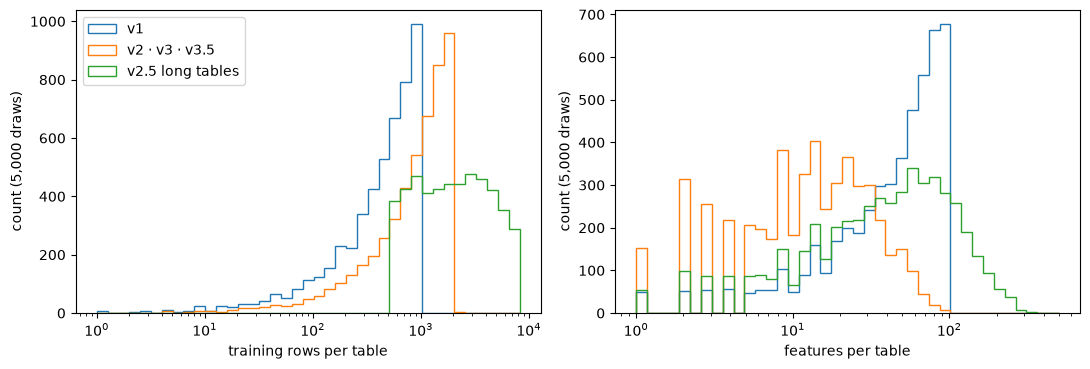

In [6]:
rng = np.random.default_rng(0)
N_DRAWS = 5_000


def draw(config):
    return np.array(
        [
            sample_table_size(
                rng,
                config.max_train_rows,
                config.n_eval_rows,
                config.max_features,
                min_train_rows=config.min_train_rows,
                log_uniform_rows=config.log_uniform_rows,
                max_cells=config.max_cells,
                feature_scale=config.feature_scale,
            )
            for _ in range(N_DRAWS)
        ]
    )


sizes = {
    "v1": np.stack(
        [rng.integers(1, v1_max_train + 1, N_DRAWS), rng.integers(1, 101, N_DRAWS)], axis=1
    ),
    "v2 · v3 · v3.5": draw(v2_paper),
    "v2.5 long tables": draw(v25_long),
}
size_rows = {}
for name, s in sizes.items():
    size_rows[name] = {
        "학습 행 중앙값": np.median(s[:, 0]),
        "학습 행 95%": np.percentile(s[:, 0], 95),
        "feature 중앙값": np.median(s[:, 1]),
        "feature 95%": np.percentile(s[:, 1], 95),
    }
display(pd.DataFrame(size_rows).T.round(0).astype(int))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, s in sizes.items():
    axes[0].hist(s[:, 0], bins=np.logspace(0, np.log10(8192), 40), histtype="step", label=name)
    axes[1].hist(s[:, 1], bins=np.logspace(0, np.log10(500), 40), histtype="step", label=name)
axes[0].set_xlabel("training rows per table")
axes[1].set_xlabel("features per table")
for ax in axes:
    ax.set_xscale("log")
    ax.set_ylabel("count (5,000 draws)")
axes[0].legend()
plt.tight_layout()
plt.show()

v1과 v2의 feature 분포가 크게 다릅니다. v1은 1~100개에서 고르게 뽑으니 중앙값이 50쯤이지만, v2는 Beta(0.95, 8)이라 중앙값이 13개, 95%가 50개 아래인 좁은 표가 대부분이고 가끔 100개가 넘는 넓은 표가 나옵니다. 실제 표 데이터에 feature가 적은 표가 많다는 것을 반영한 분포입니다. 학습 행은 v2가 상한을 2,048로 두 배 늘렸습니다. 2.5의 긴 표는 학습 행과 feature가 모두 오른쪽으로 옮겨 가서, 학습 행 중앙값이 2,000개, feature 95%가 150개쯤입니다.

## 4. 데이터셋 200개의 통계

같은 크기(학습 행 256개, 검증 행 128개)로 v1 prior bag과 graph SCM 분류 prior에서 데이터셋을 200개씩 뽑아 통계를 냅니다. feature 수는 각 prior가 정하는 대로 둡니다(v1은 묶음의 `num_features_used`, graph SCM은 3절의 규칙). v1은 학습 행의 클래스가 검증 행에 맞지 않는 데이터셋의 정답을 모두 무시 표시(−100)로 바꾸는데, 그런 데이터셋은 빼고 셉니다.

In [7]:
N_SETS = 200


def dataset_stats(x, y, n_used):
    y = y[y >= 0]
    if y.numel() == 0:  # 정답이 모두 무시 표시인 데이터셋
        return None
    counts = torch.bincount(y.long())
    counts = counts[counts > 0]
    x = x[:, :n_used]
    return {
        "클래스 수": len(counts),
        "이진 분류": len(counts) == 2,
        "가장 큰 클래스 비율": (counts.max() / counts.sum()).item(),
        "값 10종 이하인 열 비율": np.mean([v <= 10 for v in distinct_values(x, n_used)]),
        "결측값 있음": bool(torch.isnan(x).any()),
        "결측 칸 비율": torch.isnan(x).float().mean().item(),
        "feature 수": n_used,
    }


collected = {"v1 prior bag": [], "graph SCM": []}
seconds = {}
start = time.perf_counter()
while len(collected["v1 prior bag"]) < N_SETS:
    xg, yg, hp = v1_prior.sample_group(N_TRAIN)
    for i in range(xg.shape[0]):
        row = dataset_stats(xg[i], yg[i], hp["num_features_used"])
        if row is not None:
            collected["v1 prior bag"].append(row)
seconds["v1 prior bag"] = (time.perf_counter() - start) / len(collected["v1 prior bag"])

start = time.perf_counter()
while len(collected["graph SCM"]) < N_SETS:
    _, n_features = graph_cls.sample_size()
    batch = graph_cls.sample_batch(8, size=(N_TRAIN, n_features))
    for i in range(batch.x.shape[0]):
        collected["graph SCM"].append(dataset_stats(batch.x[i], batch.y[i], n_features))
seconds["graph SCM"] = (time.perf_counter() - start) / len(collected["graph SCM"])

summary = {}
for name, rows in collected.items():
    frame = pd.DataFrame(rows[:N_SETS])
    summary[name] = {
        "평균 클래스 수": frame["클래스 수"].mean(),
        "이진 분류 비율": frame["이진 분류"].mean(),
        "가장 큰 클래스 비율 (평균)": frame["가장 큰 클래스 비율"].mean(),
        "값 10종 이하인 열 비율 (평균)": frame["값 10종 이하인 열 비율"].mean(),
        "결측값이 있는 데이터셋 비율": frame["결측값 있음"].mean(),
        "결측 칸 비율 (평균)": frame["결측 칸 비율"].mean(),
        "feature 수 중앙값": frame["feature 수"].median(),
        "데이터셋 하나 만드는 시간 (ms)": 1000 * seconds[name],
    }
display(pd.DataFrame(summary).round(3))

,v1 prior bag,graph SCM
평균 클래스 수,3.095,5.275
이진 분류 비율,0.500,0.185
가장 큰 클래스 비율 (평균),0.626,0.473
값 10종 이하인 열 비율 (평균),0.106,0.495
결측값이 있는 데이터셋 비율,0.000,0.310
결측 칸 비율 (평균),0.000,0.049
feature 수 중앙값,56.000,15.000
데이터셋 하나 만드는 시간 (ms),2.498,31.715


생성기가 바뀌면서 데이터셋의 성격이 여러 군데서 달라집니다.

- **클래스**: v1은 절반이 이진 분류이고 평균 클래스 수가 3개쯤입니다(클래스 수를 뽑은 뒤 50% 확률로 2개로 둡니다). graph SCM은 이진 분류가 20% 안팎이고 평균 5개쯤으로 다중 클래스가 대부분입니다. 가장 큰 클래스 비율도 graph SCM이 낮아 클래스가 더 고르게 나뉩니다.
- **범주형·구간 열**: 값이 10종 이하인 열이 v1은 10%쯤, graph SCM은 절반 가까이입니다. v2 논문이 prior에 범주형 feature와 이산화한 간선을 넣은 것과 같은 방향입니다.
- **결측값**: v1(공개 체크포인트 설정)은 결측값이 없고, graph SCM은 데이터셋 30%쯤에 결측값이 있습니다. 결측값을 넣는 비율은 v2 논문에 없어서 이 저장소가 정했습니다.
- **feature 수**: 같은 학습 행 수여도 v1은 feature 중앙값이 50개 넘고, graph SCM은 15개 안팎입니다(3절의 분포).
- **시간**: graph SCM이 데이터셋 하나에 10배 넘게 걸립니다. 그래서 학습 때는 GPU마다 prior를 만드는 worker를 여러 개 띄웁니다(3.5 multitask는 두 task가 worker를 나눠 씁니다).

시간은 CPU 하나에서 잰 값이고, 실행마다 조금씩 다릅니다. graph SCM의 통계도 실행마다 몇 %씩 달라집니다. TabICL 생성기가 파이썬 프로세스의 문자열 hash 시드(`PYTHONHASHSEED`)에 따라 다른 데이터셋을 만들기 때문입니다(학습 스크립트는 이 시드를 1로 고정합니다).

## 5. 정리

| 버전 | 생성기 | task | 학습 표 크기 | 데이터셋의 성격 | 자세히 |
|---|---|---|---|---|---|
| v1 | prior bag: MLP(SCM 또는 BNN) + GP, 묶음 8개가 하이퍼파라미터 공유 | 분류 | 학습 행 1~999, feature 1~100 균등 | 연속값 위주, 이진 분류가 절반, 결측값 없음 | [02_tabpfn/01](../02_tabpfn/01_scm_primer.ipynb)·[02](../02_tabpfn/02_random_scm_datasets.ipynb)·[03](../02_tabpfn/03_bnn_primer.ipynb)·[05](../02_tabpfn/05_tabpfn_paper_prior.ipynb) |
| v2 | 논문: 무작위 그래프 SCM (코드 비공개) → 이 저장소: TabICL graph SCM | 분류, 회귀 | 학습 행 1~2,048 균등, feature Beta(0.95, 8) × 160, 셀 75,000 | 다중 클래스 위주, 범주형·구간 열 절반 가까이, 결측값 데이터셋 30% | [03_tabpfn_v2/03](../03_tabpfn_v2/03_prior_graph_and_edges.ipynb)·[04](../03_tabpfn_v2/04_prior_from_graph_to_table.ipynb)·[07](../03_tabpfn_v2/07_tabicl_prior.ipynb) |
| 2.5 | v2와 같음 | 분류, 회귀 | v2 크기로 학습한 뒤 학습 행 512~8,192 log 균등, feature 500, 셀 400,000으로 이어 학습 | v2와 같고 표가 큼 | [04_tabpfn_v2_5/03](../04_tabpfn_v2_5/03_long_tables.ipynb) |
| 3 | v2와 같음 | 분류, 회귀 | v2와 같음 | v2와 같음 | [05_tabpfn_v3/01](../05_tabpfn_v3/01_overview_and_cell_encoder.ipynb) |
| 3.5 | v2와 같음, task마다 prior 하나씩 | 분류 + 회귀 한 모델 | v2와 같음 | v2와 같음 | [06_tabpfn_v3_5/01](../06_tabpfn_v3_5/01_changes_and_multitask.ipynb) 5절 |

prior가 크게 바뀐 것은 v1 → v2 한 번입니다. 그때 다중 클래스, 범주형 feature, 결측값, 회귀, 그리고 feature가 적은 표가 많은 크기 분포가 들어왔습니다. 그 뒤 버전들은 생성기를 그대로 두고 표 크기(2.5)와 task를 섞는 방식(3.5)만 바꿨습니다. 3·3.5 보고서도 prior가 2.5와 같다고만 적었고 세부는 공개하지 않았습니다.